In [ ]:
# Imports and data directory
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Reproduce").is_dir())
from melon_pkg.plotting import *
DATA_ROOT = Path(os.environ.get("MELON_PUBLISHED_DATA", repo / "Published_Data_non_NASH"))
DATA = DATA_ROOT / "03_Mouse_E13"
assert DATA.is_dir(), "Place Published_Data_non_NASH beside Reproduce, or set MELON_PUBLISHED_DATA."


In [ ]:
# Input data
import anndata as ad
from melon_pkg.cli_run import normalize_df

modalities = ["RNA", "ATAC"]
rna = ad.read_h5ad(DATA / "01_source_data/adata_RNA.h5ad")
atac = ad.read_h5ad(DATA / "01_source_data/adata_ATAC.h5ad")
barcodes = rna.obs_names.intersection(atac.obs_names, sort=False)
coords = pd.DataFrame(rna[barcodes].obsm["spatial"], index=barcodes, columns=["x", "y"])

rna = normalize_df(rna[barcodes].to_df(), "RNA", target_sum=1e4)
atac = normalize_df(atac[barcodes].to_df(), "ATAC", target_sum=1e4)
features = [rna.to_numpy(dtype=np.float32), atac.to_numpy(dtype=np.float32)]


In [ ]:
# Parameters
config = {
    'epochs': 100,
    'batch_size': 2048,
    'embed_dim': 128,
    'training_seed': 2021,
    'learning_rate': 0.001,
    'weight_decay': 1e-05,
    'temperature': 0.1,
    'training_spatial_k': 16,
    'export_spatial_k': 16,
    'augment_p': 0.8,
    'augmentations': ['gaussian_noise', 'feature_dropout', 'neighbor_mix'],
    'shuffle_batches': True,
    'clustering_seed': 2025,
    'target_clusters': 14,
    'clustering_neighbors': 10,
    'leiden_resolution': 1.0,
}


In [ ]:
# Spatial graph and augmented views
import torch
from torch import nn
from types import MethodType
import pytorch_lightning as pl
from melon_pkg.data import DualAugDataModule, SpatialOmicsAugmentations
from melon_pkg.model import SpotTokenAdapter
from melon_pkg.models.mmfusion import MMFusion
from melon_pkg.pl_modules.melon import MELONModel
from melon_pkg.utils import build_knn_mask
from melon_pkg.embedding import export_embedding

pl.seed_everything(config["training_seed"], workers=True)
tensors = [torch.tensor(x, dtype=torch.float32) for x in features]
xy = torch.as_tensor(coords.to_numpy(), dtype=torch.float32)
mask, weights = build_knn_mask(xy, k=config["training_spatial_k"],
                               include_self=True, return_weights=True, symmetric=True)
augmentation = SpatialOmicsAugmentations
aug = dict(augmentations=config["augmentations"], p=config["augment_p"])
data = DualAugDataModule(
    mods_raw=tensors, coords=xy, neighbor_mask=mask, neighbor_weight=weights,
    augmentA=augmentation(**aug), augmentB=augmentation(**aug),
    batch_size=config["batch_size"], shuffle=config["shuffle_batches"],
    spot_tokenization=True,
)


In [ ]:
# MELON model
dim = config["embed_dim"]
encoder = MMFusion(
    encoders=[nn.Sequential(nn.Linear(x.shape[1], dim), nn.ReLU(), nn.Linear(dim, dim))
              for x in tensors],
    input_adapters=[SpotTokenAdapter() for _ in tensors],
    embed_dim=dim, fusion="concat", pool="tokens", n_heads=8, n_layers=1,
)
model = MELONModel(
    encoder=encoder, projection=MELONModel._build_mlp(dim, 256, dim),
    optim_kwargs={"lr": config["learning_rate"], "weight_decay": config["weight_decay"]},
    loss_kwargs={"temperature": config["temperature"]},
    neighborhood_cfg={"hidden_dim": 64, "heads": 8, "dropout": 0.1,
                      "k_neighbors": config["training_spatial_k"], "include_self": True},
)
def configure_optimizers(self):
    return torch.optim.Adam(self.parameters(), **self.optim_kwargs, betas=(0.9, 0.999))
model.configure_optimizers = MethodType(configure_optimizers, model)


In [ ]:
# Train and embed
trainer = pl.Trainer(max_epochs=config["epochs"], accelerator="cpu", devices=1,
                     logger=False, enable_checkpointing=False, deterministic=True)
trainer.fit(model, datamodule=data)
embedding = pd.DataFrame(
    export_embedding(model, tensors, xy, spatial_k=config["export_spatial_k"]),
    index=coords.index,
)
display({"spots": len(embedding), "embedding_dimensions": embedding.shape[1]})


{'spots': 2187, 'embedding_dimensions': 128}

In [ ]:
# Spatial clustering
from melon_pkg.cli_cluster import leiden_clustering
labels = leiden_clustering(
    embedding.to_numpy(), n_clusters=config["target_clusters"],
    n_neighbors=config["clustering_neighbors"], seed=config["clustering_seed"],
    resolution=config["leiden_resolution"],
)
domains = pd.Series(labels, index=embedding.index, name="MELON")
display({"spatial_domains": domains.nunique()})


{'spatial_domains': 14}

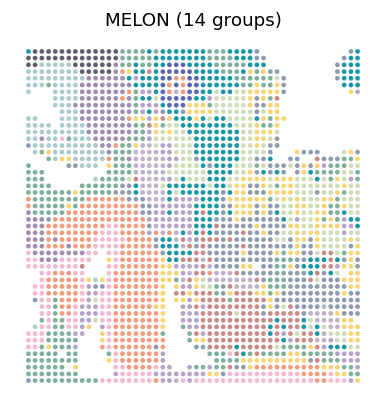

In [ ]:
# Spatial plot
plot_data = coords.loc[embedding.index].copy()
plot_data["MELON"] = domains
show(spatial_panels(plot_data, ["MELON"], ncols=1))
